<a href="https://colab.research.google.com/github/sukritmodak/MICE_MODEL_MUTATION/blob/main/Welcome_to_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install biopython pandas matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 24.1 MB/s  0:00:00


In [2]:
from google.colab import files

uploaded = files.upload()

Saving drive-download-20261031T121008Z-1-001.zip to drive-download-20261031T121008Z-1-001.zip


In [3]:
import zipfile
import os

zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall('/content/OPA1_project')

print("Files extracted successfully!")

Files extracted successfully!


In [4]:
import os

folder = "/content/OPA1_project"

for root, dirs, files_list in os.walk(folder):
    for file in files_list:
        if file.endswith((".cif", ".pdb")):
            print(os.path.join(root, file))

/content/OPA1_project/EM STRUCTURES/G300E_EM.cif
/content/OPA1_project/EM STRUCTURES/WTOPA1_EM.cif
/content/OPA1_project/EM STRUCTURES/I382M_EM.cif
/content/OPA1_project/EM STRUCTURES/R445H_EM.cif
/content/OPA1_project/EM STRUCTURES/C551Y_EM.cif
/content/OPA1_project/EM STRUCTURES/fold_opa1_structure/fold_opa1_structure_model_1.cif
/content/OPA1_project/EM STRUCTURES/fold_opa1_structure/fold_opa1_structure_model_4.cif
/content/OPA1_project/EM STRUCTURES/fold_opa1_structure/fold_opa1_structure_model_3.cif
/content/OPA1_project/EM STRUCTURES/fold_opa1_structure/fold_opa1_structure_model_2.cif
/content/OPA1_project/EM STRUCTURES/fold_opa1_structure/fold_opa1_structure_model_0.cif
/content/OPA1_project/EM STRUCTURES/fold_opa1_structure/templates/fold_opa1_structure_template_hit_3_chains_a.cif
/content/OPA1_project/EM STRUCTURES/fold_opa1_structure/templates/fold_opa1_structure_template_hit_1_chains_a.cif
/content/OPA1_project/EM STRUCTURES/fold_opa1_structure/templates/fold_opa1_structure_

In [5]:
import os

folder = "/content/OPA1_project"

for root, dirs, files in os.walk(folder):
    for file in files:
        if file.endswith((".cif", ".pdb")):
            print(file)

G300E_EM.cif
WTOPA1_EM.cif
I382M_EM.cif
R445H_EM.cif
C551Y_EM.cif
fold_opa1_structure_model_1.cif
fold_opa1_structure_model_4.cif
fold_opa1_structure_model_3.cif
fold_opa1_structure_model_2.cif
fold_opa1_structure_model_0.cif
fold_opa1_structure_template_hit_3_chains_a.cif
fold_opa1_structure_template_hit_1_chains_a.cif
fold_opa1_structure_template_hit_0_chains_a.cif
fold_opa1_structure_template_hit_2_chains_a.cif
C551Y.cif
G300E.pdb
I382M.cif
WTOPA1.pdb
R445H.cif


In [7]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file == "WTOPA1_EM.cif":
            print("Found file:", os.path.join(root, file))

Found file: /content/OPA1_project/EM STRUCTURES/WTOPA1_EM.cif


In [8]:
import os

folder = "/content/OPA1_project"

# Search all folders for protein files
file_paths = {}

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file in [
            "WTOPA1_EM.cif",
            "G300E_EM.cif",
            "I382M_EM.cif",
            "R445H_EM.cif",
            "C551Y_EM.cif"
        ]:
            file_paths[file] = os.path.join(root, file)

print(file_paths)

{'G300E_EM.cif': '/content/OPA1_project/EM STRUCTURES/G300E_EM.cif', 'WTOPA1_EM.cif': '/content/OPA1_project/EM STRUCTURES/WTOPA1_EM.cif', 'I382M_EM.cif': '/content/OPA1_project/EM STRUCTURES/I382M_EM.cif', 'R445H_EM.cif': '/content/OPA1_project/EM STRUCTURES/R445H_EM.cif', 'C551Y_EM.cif': '/content/OPA1_project/EM STRUCTURES/C551Y_EM.cif'}


In [12]:
def load_structure(filename):

    path = file_paths[filename]

    if filename.endswith(".cif"):
        parser = MMCIFParser(QUIET=True)
    else:
        parser = PDBParser(QUIET=True)

    structure = parser.get_structure(filename, path)

    return structure

In [13]:
print("My OPA1 files are ready!")

print(file_paths)

My OPA1 files are ready!
{'G300E_EM.cif': '/content/OPA1_project/EM STRUCTURES/G300E_EM.cif', 'WTOPA1_EM.cif': '/content/OPA1_project/EM STRUCTURES/WTOPA1_EM.cif', 'I382M_EM.cif': '/content/OPA1_project/EM STRUCTURES/I382M_EM.cif', 'R445H_EM.cif': '/content/OPA1_project/EM STRUCTURES/R445H_EM.cif', 'C551Y_EM.cif': '/content/OPA1_project/EM STRUCTURES/C551Y_EM.cif'}


Loading WT protein...
Processing: WT
Processing: G300E
Processing: I382M
Processing: R445H
Processing: C551Y

RMSD RESULTS


,Mutation,RMSD (Å),Aligned atoms
0,WT,0.000,960
1,G300E,0.369,959
2,I382M,0.218,960
3,R445H,0.243,960
4,C551Y,0.314,960


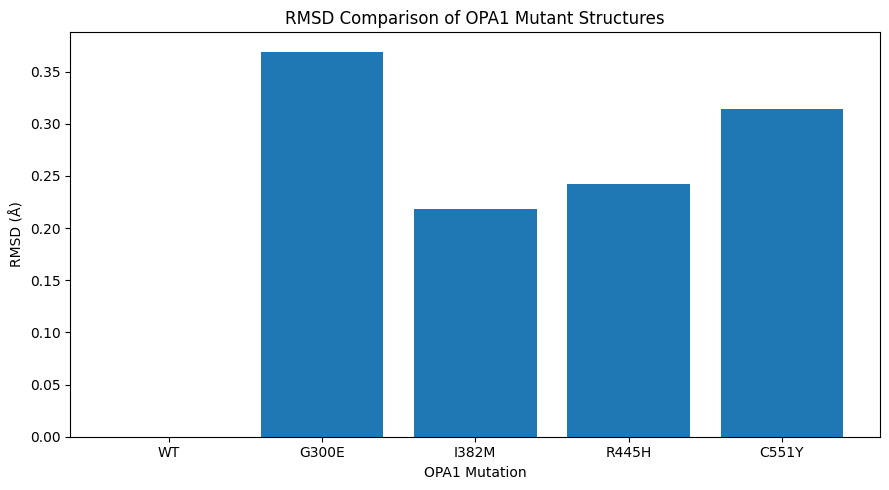

Graph saved successfully!


In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Bio.PDB import MMCIFParser, Superimposer
from Bio.PDB.Polypeptide import protein_letters_3to1
from Bio.Align import PairwiseAligner

# 1. Protein file locations
structures = {
    "WT": "WTOPA1_EM.cif",
    "G300E": "G300E_EM.cif",
    "I382M": "I382M_EM.cif",
    "R445H": "R445H_EM.cif",
    "C551Y": "C551Y_EM.cif"
}

# 2. Load structure
def load_structure(filename):
    path = file_paths[filename]

    parser = MMCIFParser(QUIET=True)
    return parser.get_structure(filename, path)

# 3. Get protein residues
def get_residues(structure):
    best = []

    for chain in structure[0]:
        residues = [
            r for r in chain
            if r.id[0] == " "
            and "CA" in r
            and r.resname in protein_letters_3to1
        ]

        if len(residues) > len(best):
            best = residues

    return best

# 4. Convert residues to sequence
def get_sequence(residues):
    return "".join(
        protein_letters_3to1[r.resname]
        for r in residues
    )

# 5. Calculate RMSD
def calculate_rmsd(reference, mutant):

    ref = get_residues(reference)
    mut = get_residues(mutant)

    ref_seq = get_sequence(ref)
    mut_seq = get_sequence(mut)

    aligner = PairwiseAligner()
    aligner.mode = "global"
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -5
    aligner.extend_gap_score = -0.5

    alignment = aligner.align(ref_seq, mut_seq)[0]

    ref_atoms = []
    mut_atoms = []

    for ref_block, mut_block in zip(*alignment.aligned):
        for i, j in zip(
            range(ref_block[0], ref_block[1]),
            range(mut_block[0], mut_block[1])
        ):
            ref_atoms.append(ref[i]["CA"])
            mut_atoms.append(mut[j]["CA"])

    if len(ref_atoms) < 3:
        raise ValueError("Too few matching atoms")

    sup = Superimposer()
    sup.set_atoms(ref_atoms, mut_atoms)

    return sup.rms, len(ref_atoms)

# 6. Load WT
print("Loading WT protein...")

wt = load_structure(structures["WT"])

results = []

# 7. Compare each mutant
for name, filename in structures.items():

    print("Processing:", name)

    if name == "WT":
        results.append({
            "Mutation": name,
            "RMSD (Å)": 0.0,
            "Aligned atoms": len(get_residues(wt))
        })
    else:
        mutant = load_structure(filename)

        rmsd, count = calculate_rmsd(wt, mutant)

        results.append({
            "Mutation": name,
            "RMSD (Å)": rmsd,
            "Aligned atoms": count
        })

# 8. Display table
df = pd.DataFrame(results)

print("\nRMSD RESULTS")
display(df.round(3))

# 9. Create graph
plt.figure(figsize=(9, 5))

plt.bar(df["Mutation"], df["RMSD (Å)"])

plt.title("RMSD Comparison of OPA1 Mutant Structures")
plt.xlabel("OPA1 Mutation")
plt.ylabel("RMSD (Å)")

plt.tight_layout()
plt.savefig("/content/OPA1_RMSD_comparison.png", dpi=300)

plt.show()

print("Graph saved successfully!")

In [15]:
from google.colab import files

files.download("/content/OPA1_RMSD_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Find your PSIPRED files


In [16]:
import os

for root, dirs, files in os.walk("/content/OPA1_project"):
    for file in files:
        if file.endswith(".ss2"):
            print(os.path.join(root, file))

/content/OPA1_project/PSIPRED/WTOPA1/0b019d2e-5062-11f1-af7d-00163e100466.ss2
/content/OPA1_project/PSIPRED/R445H/d9bbd5da-5062-11f1-abc7-00163e100466.ss2
/content/OPA1_project/PSIPRED/G300E/8d789762-5062-11f1-abee-00163e100466.ss2
/content/OPA1_project/PSIPRED/I382M/b14c4d78-5062-11f1-92a8-00163e100466.ss2
/content/OPA1_project/PSIPRED/C551Y/f6fd0db2-5062-11f1-ba96-00163e100466.ss2


WT : 960 residues
G300E : 960 residues
I382M : 960 residues
R445H : 960 residues
C551Y : 960 residues


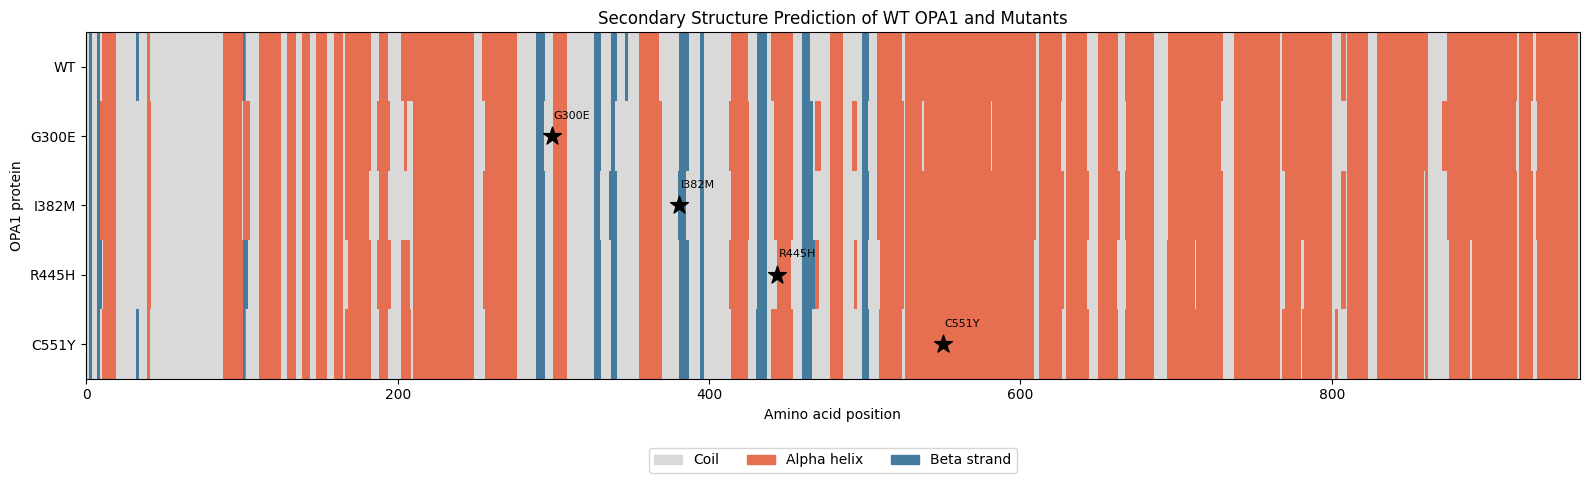

Secondary structure figure created!


In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# PSIPRED file locations
ss2_files = {
    "WT": "/content/OPA1_project/PSIPRED/WTOPA1/0b019d2e-5062-11f1-af7d-00163e100466.ss2",
    "G300E": "/content/OPA1_project/PSIPRED/G300E/8d789762-5062-11f1-abee-00163e100466.ss2",
    "I382M": "/content/OPA1_project/PSIPRED/I382M/b14c4d78-5062-11f1-92a8-00163e100466.ss2",
    "R445H": "/content/OPA1_project/PSIPRED/R445H/d9bbd5da-5062-11f1-abc7-00163e100466.ss2",
    "C551Y": "/content/OPA1_project/PSIPRED/C551Y/f6fd0db2-5062-11f1-ba96-00163e100466.ss2"
}

# Read PSIPRED files
def read_ss2(path):
    positions = []
    amino_acids = []
    structures = []

    with open(path, "r") as f:
        for line in f:
            line = line.strip()

            if not line or line.startswith("#"):
                continue

            parts = line.split()

            if len(parts) < 3:
                continue

            try:
                position = int(parts[0])
            except ValueError:
                continue

            positions.append(position)
            amino_acids.append(parts[1])
            structures.append(parts[2])

    return pd.DataFrame({
        "Position": positions,
        "AA": amino_acids,
        "SS": structures
    })

# Load all predictions
data = {}

for name, path in ss2_files.items():
    data[name] = read_ss2(path)

    print(name, ":", len(data[name]), "residues")

# Secondary structure codes
ss_codes = {
    "C": 0,
    "H": 1,
    "E": 2
}

# Build matrix for plotting
max_length = max(len(df) for df in data.values())

matrix = np.full((len(data), max_length), np.nan)

for row, (name, df) in enumerate(data.items()):
    matrix[row, :len(df)] = [
        ss_codes.get(ss, 0)
        for ss in df["SS"]
    ]

# Plot
fig, ax = plt.subplots(figsize=(16, 5))

cmap = ListedColormap([
    "#D9D9D9",  # Coil
    "#E76F51",  # Helix
    "#457B9D"   # Beta strand
])

ax.imshow(
    matrix,
    aspect="auto",
    interpolation="nearest",
    cmap=cmap,
    vmin=0,
    vmax=2
)

# Labels
ax.set_yticks(range(len(data)))
ax.set_yticklabels(list(data.keys()))

ax.set_xlabel("Amino acid position")
ax.set_ylabel("OPA1 protein")

ax.set_title(
    "Secondary Structure Prediction of WT OPA1 and Mutants"
)

# Mutation positions
mutations = {
    "G300E": 300,
    "I382M": 382,
    "R445H": 445,
    "C551Y": 551
}

for row, name in enumerate(data.keys()):
    if name in mutations:
        position = mutations[name]

        ax.scatter(
            position - 1,
            row,
            marker="*",
            s=180,
            color="black",
            zorder=5
        )

        ax.text(
            position,
            row - 0.25,
            name,
            fontsize=8,
            color="black"
        )

# Legend
legend_items = [
    Patch(color="#D9D9D9", label="Coil"),
    Patch(color="#E76F51", label="Alpha helix"),
    Patch(color="#457B9D", label="Beta strand")
]

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3
)

plt.tight_layout()

plt.savefig(
    "/content/OPA1_secondary_structure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Secondary structure figure created!")

In [18]:
from google.colab import files

files.download("/content/OPA1_secondary_structure.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import os

for root, dirs, files in os.walk("/content/OPA1_project"):
    for file in files:
        if any(word in file.lower() for word in
               ["dynamut", "stability", "ddg", "energy"]):
            print(os.path.join(root, file))

In [20]:
import os

for item in os.listdir("/content/OPA1_project"):
    print(item)

misSense3d
OPA1_MMP
PSIPRED
DYNAMUT2
EM STRUCTURES


In [21]:
import os

folder = "/content/OPA1_project/DYNAMUT2"

for root, dirs, files in os.walk(folder):
    for file in files:
        print(os.path.join(root, file))

/content/OPA1_project/DYNAMUT2/R445H INFO.png
/content/OPA1_project/DYNAMUT2/I382M INFO.png
/content/OPA1_project/DYNAMUT2/C551Y INFO.png
/content/OPA1_project/DYNAMUT2/wt_177666866684_A_R445H.pse
/content/OPA1_project/DYNAMUT2/wt_17766686431_A_G300E.pse
/content/OPA1_project/DYNAMUT2/G300E INFO.png
/content/OPA1_project/DYNAMUT2/wt_177666868013_A_I382M.pse
/content/OPA1_project/DYNAMUT2/wt_17766686876_A_C551Y.pse


G300E INFO.png


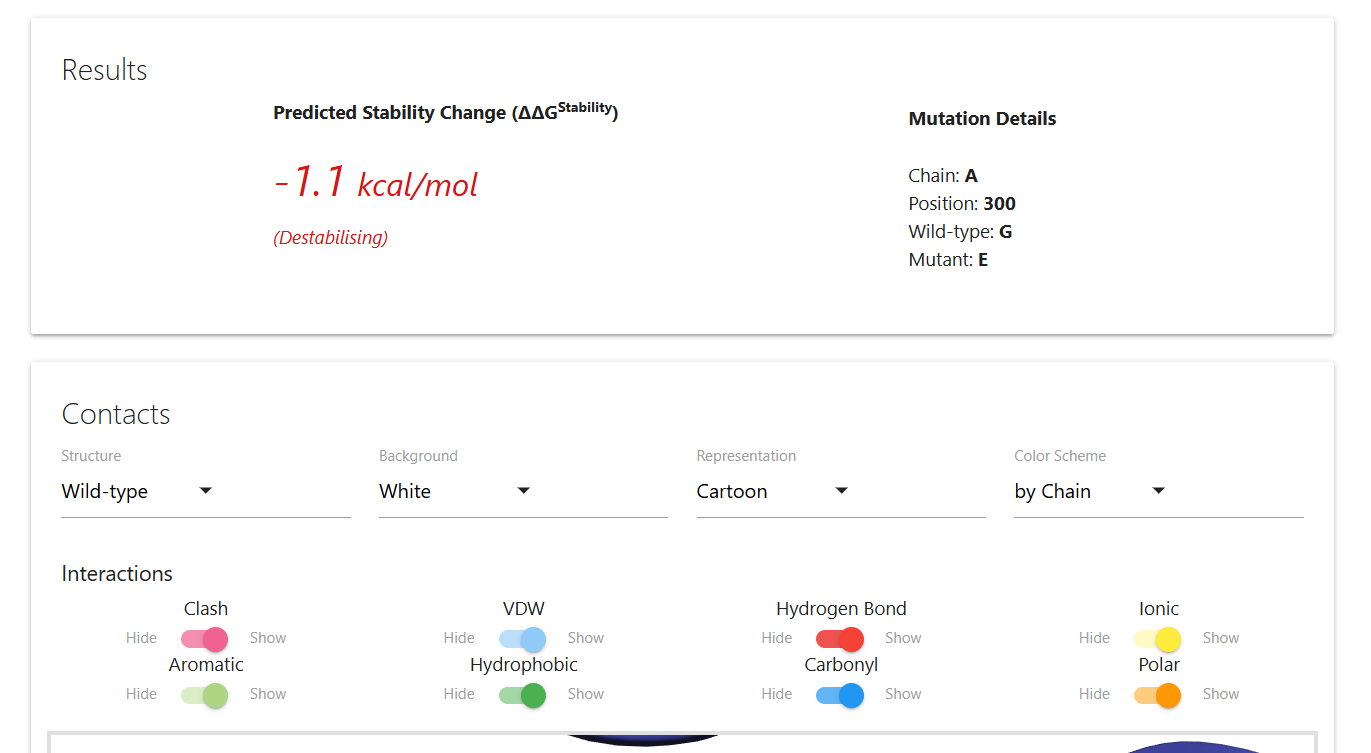

R445H INFO.png


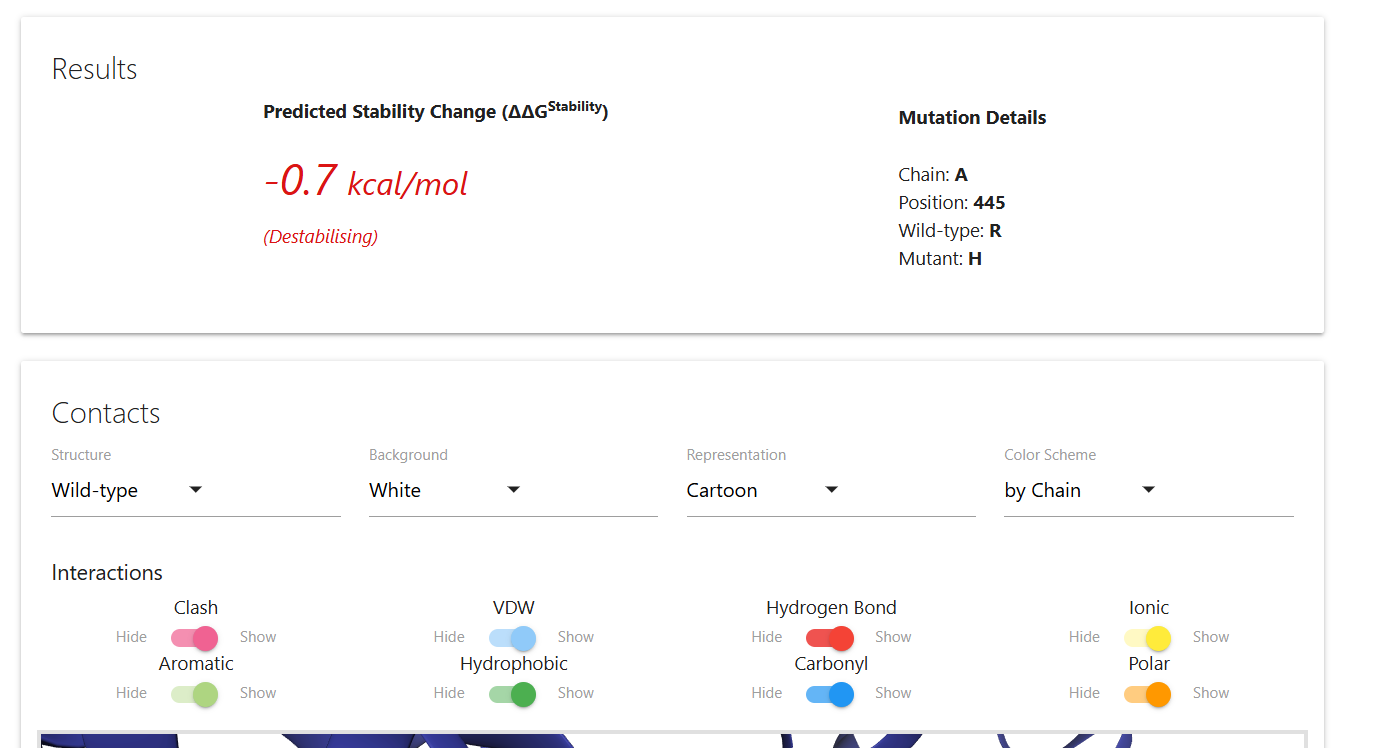

I382M INFO.png


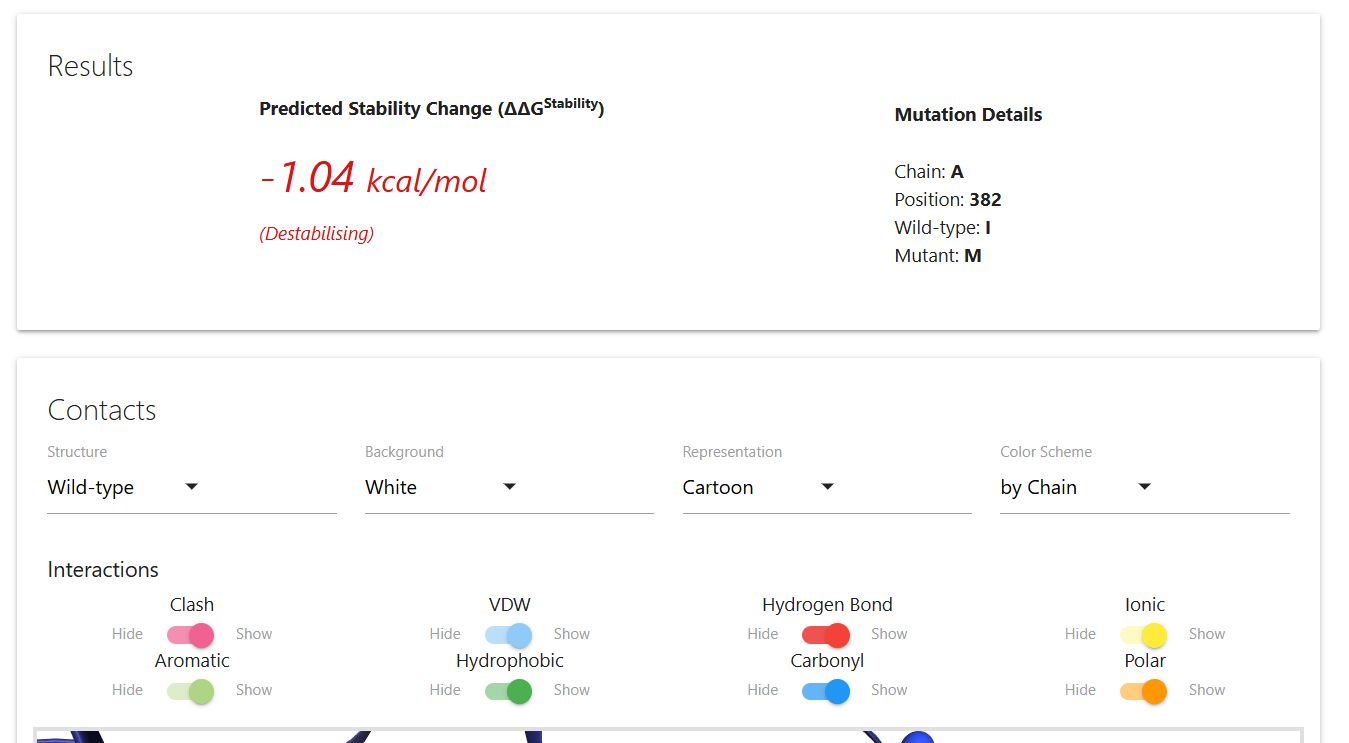

C551Y INFO.png


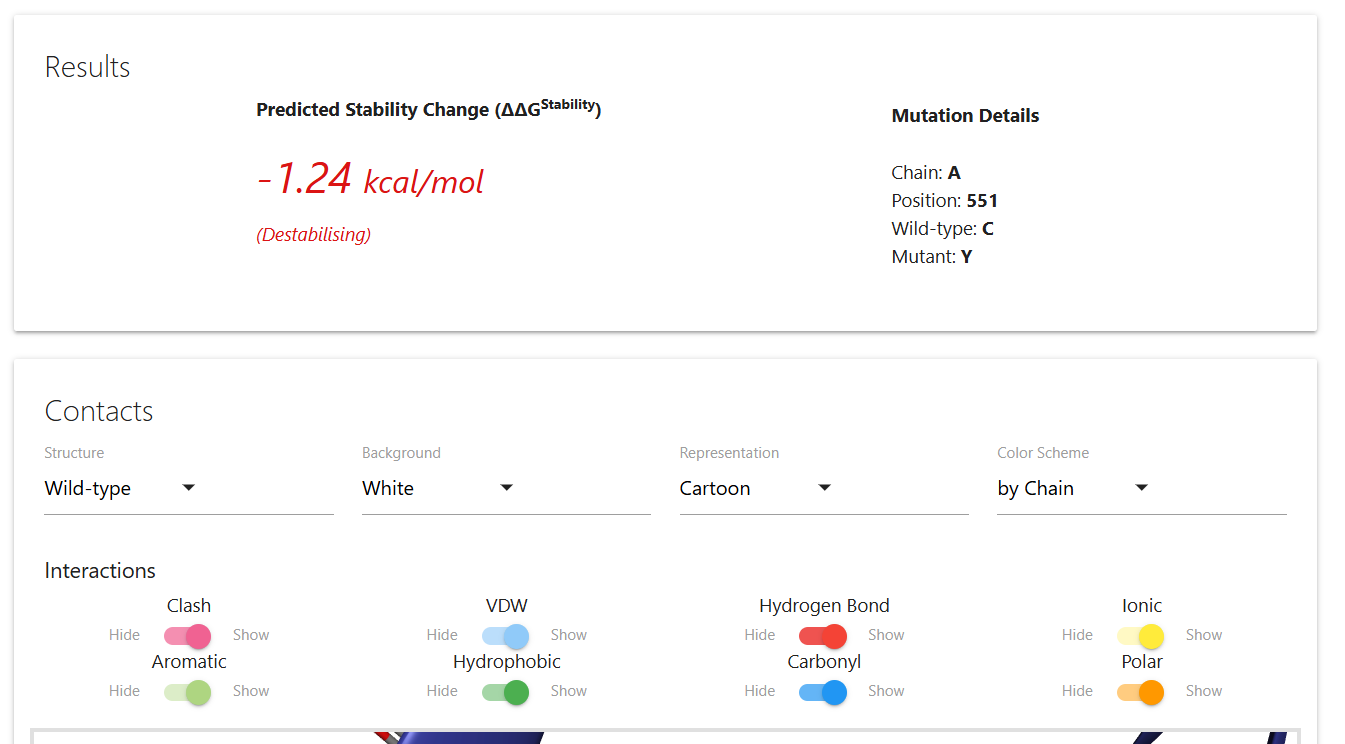

In [22]:
from PIL import Image
from IPython.display import display
import os

folder = "/content/OPA1_project/DYNAMUT2"

for name in ["G300E INFO.png", "R445H INFO.png",
             "I382M INFO.png", "C551Y INFO.png"]:
    path = os.path.join(folder, name)
    print(name)
    display(Image.open(path))

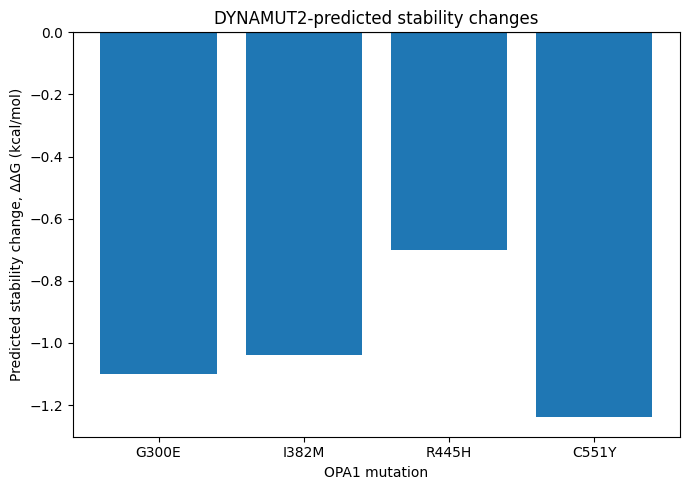

In [23]:
import matplotlib.pyplot as plt

mutations = ["G300E", "I382M", "R445H", "C551Y"]
ddg = [-1.10, -1.04, -0.70, -1.24]

plt.figure(figsize=(7, 5))
bars = plt.bar(mutations, ddg)

plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Predicted stability change, ΔΔG (kcal/mol)")
plt.xlabel("OPA1 mutation")
plt.title("DYNAMUT2-predicted stability changes")
plt.tight_layout()

plt.savefig(
    "/content/OPA1_project/DYNAMUT2_stability.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [24]:
import os

path = "/content/OPA1_project/DYNAMUT2_stability.png"
print("Figure saved:", os.path.exists(path))

Figure saved: True


In [25]:
import os

path = "/content/OPA1_project/PSIPRED_secondary_structure.png"
print("Figure saved:", os.path.exists(path))

Figure saved: False


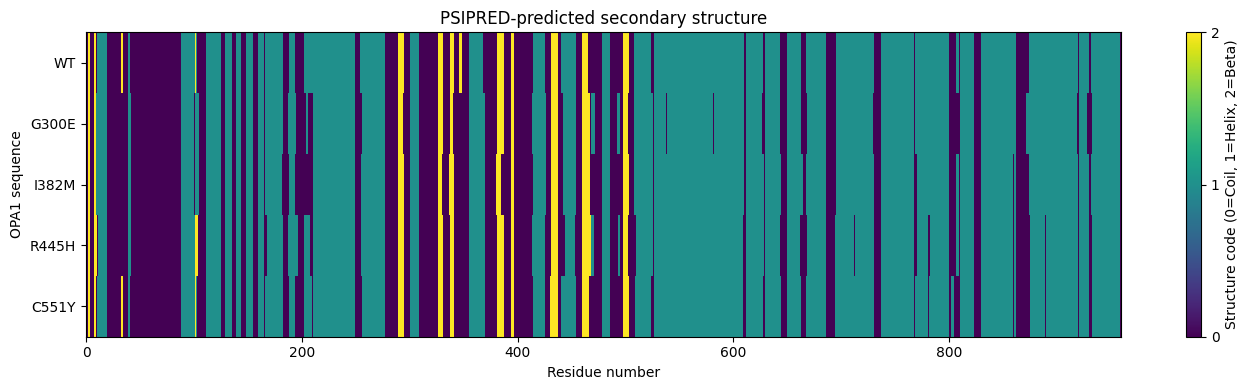

Saved figure: /content/OPA1_project/PSIPRED_secondary_structure.png


In [26]:
import os
import matplotlib.pyplot as plt
import numpy as np

base = "/content/OPA1_project/PSIPRED"

files = {
    "WT": "WTOPA1/0b019d2e-5062-11f1-af7d-00163e100466.ss2",
    "G300E": "G300E/8d789762-5062-11f1-abee-00163e100466.ss2",
    "I382M": "I382M/b14c4d78-5062-11f1-92a8-00163e100466.ss2",
    "R445H": "R445H/d9bbd5da-5062-11f1-abc7-00163e100466.ss2",
    "C551Y": "C551Y/f6fd0db2-5062-11f1-ba96-00163e100466.ss2"
}

# PSIPRED codes: H = helix, E = beta strand, C = coil
codes = {"C": 0, "H": 1, "E": 2}
labels = list(files.keys())
rows = []

for label, relative_path in files.items():
    path = os.path.join(base, relative_path)

    if not os.path.exists(path):
        raise FileNotFoundError(f"Could not find: {path}")

    structure = []
    with open(path) as f:
        for line in f:
            parts = line.split()
            if len(parts) >= 3 and parts[0].isdigit():
                structure.append(codes.get(parts[2], 0))

    rows.append(structure)

# Keep the same sequence length across rows for plotting
max_length = max(len(row) for row in rows)
matrix = np.full((len(rows), max_length), np.nan)

for i, row in enumerate(rows):
    matrix[i, :len(row)] = row

plt.figure(figsize=(14, 4))
plt.imshow(matrix, aspect="auto", interpolation="nearest",
           cmap="viridis", vmin=0, vmax=2)

plt.yticks(range(len(labels)), labels)
plt.xlabel("Residue number")
plt.ylabel("OPA1 sequence")
plt.title("PSIPRED-predicted secondary structure")
plt.colorbar(ticks=[0, 1, 2], label="Structure code (0=Coil, 1=Helix, 2=Beta)")
plt.tight_layout()

output = "/content/OPA1_project/PSIPRED_secondary_structure.png"
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", output)

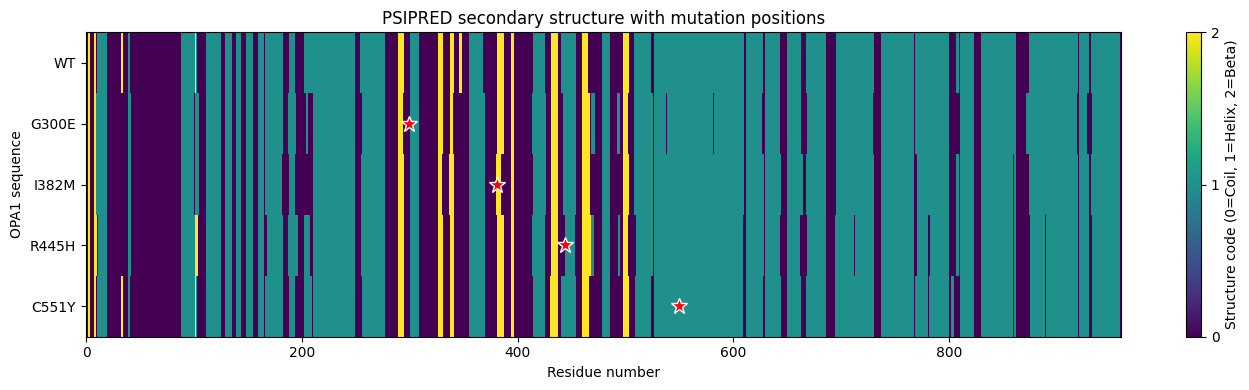

Saved figure: /content/OPA1_project/PSIPRED_secondary_structure_marked.png


In [27]:
import os
import matplotlib.pyplot as plt
import numpy as np

base = "/content/OPA1_project/PSIPRED"

files = {
    "WT": "WTOPA1/0b019d2e-5062-11f1-af7d-00163e100466.ss2",
    "G300E": "G300E/8d789762-5062-11f1-abee-00163e100466.ss2",
    "I382M": "I382M/b14c4d78-5062-11f1-92a8-00163e100466.ss2",
    "R445H": "R445H/d9bbd5da-5062-11f1-abc7-00163e100466.ss2",
    "C551Y": "C551Y/f6fd0db2-5062-11f1-ba96-00163e100466.ss2"
}

codes = {"C": 0, "H": 1, "E": 2}
labels = list(files.keys())
rows = []

for label, relative_path in files.items():
    path = os.path.join(base, relative_path)
    structure = []

    with open(path) as f:
        for line in f:
            parts = line.split()
            if len(parts) >= 3 and parts[0].isdigit():
                structure.append(codes.get(parts[2], 0))

    rows.append(structure)

max_length = max(map(len, rows))
matrix = np.full((len(rows), max_length), np.nan)

for i, row in enumerate(rows):
    matrix[i, :len(row)] = row

fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(
    matrix, aspect="auto", interpolation="nearest",
    cmap="viridis", vmin=0, vmax=2
)

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_xlabel("Residue number")
ax.set_ylabel("OPA1 sequence")
ax.set_title("PSIPRED secondary structure with mutation positions")

# Mark each mutation position on its corresponding row
mutation_positions = {
    "G300E": 300,
    "I382M": 382,
    "R445H": 445,
    "C551Y": 551
}

for row_index, label in enumerate(labels):
    if label in mutation_positions:
        position = mutation_positions[label]
        ax.plot(
            position - 1, row_index,
            marker="*", color="red",
            markersize=12, markeredgecolor="white"
        )

cbar = fig.colorbar(im, ax=ax, ticks=[0, 1, 2])
cbar.set_label("Structure code (0=Coil, 1=Helix, 2=Beta)")

plt.tight_layout()

output = "/content/OPA1_project/PSIPRED_secondary_structure_marked.png"
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", output)

In [28]:
import os

path = "/content/OPA1_project/RMSD_comparison.png"
print("RMSD figure saved:", os.path.exists(path))

RMSD figure saved: False


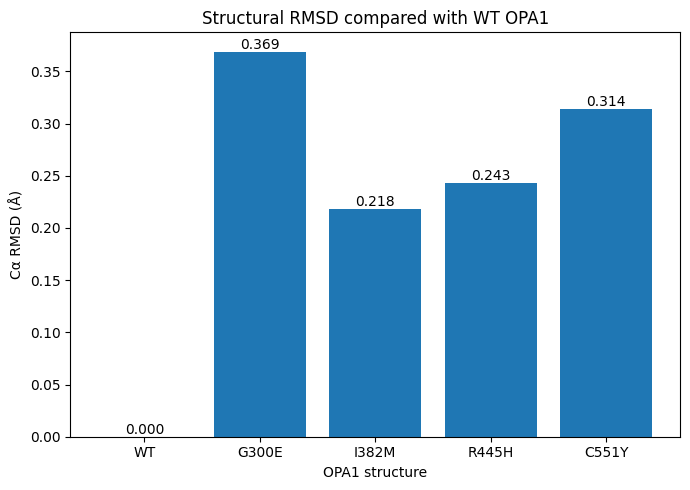

Saved figure: /content/OPA1_project/RMSD_comparison.png


In [29]:
import matplotlib.pyplot as plt

mutations = ["WT", "G300E", "I382M", "R445H", "C551Y"]
rmsd = [0.0, 0.369, 0.218, 0.243, 0.314]

plt.figure(figsize=(7, 5))
bars = plt.bar(mutations, rmsd)

plt.ylabel("Cα RMSD (Å)")
plt.xlabel("OPA1 structure")
plt.title("Structural RMSD compared with WT OPA1")

plt.bar_label(bars, fmt="%.3f")
plt.tight_layout()

output = "/content/OPA1_project/RMSD_comparison.png"
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", output)

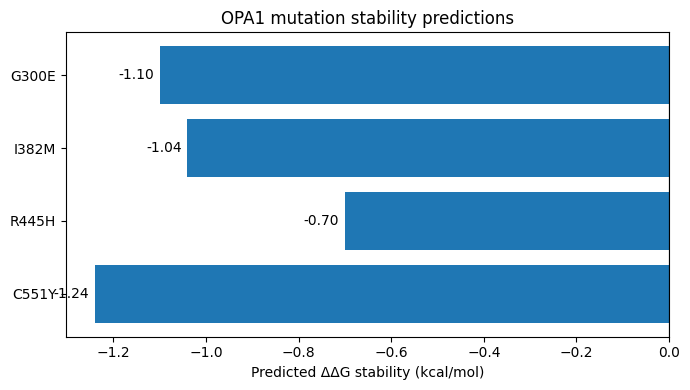

Saved figure: /content/OPA1_project/DYNAMUT2_stability_summary.png


In [30]:
import matplotlib.pyplot as plt

mutations = ["G300E", "I382M", "R445H", "C551Y"]
ddg = [-1.10, -1.04, -0.70, -1.24]

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.barh(mutations, ddg)
ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel("Predicted ΔΔG stability (kcal/mol)")
ax.set_title("OPA1 mutation stability predictions")
ax.invert_yaxis()

ax.bar_label(bars, fmt="%.2f", padding=4)
plt.tight_layout()

output = "/content/OPA1_project/DYNAMUT2_stability_summary.png"
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", output)

In [31]:
import os
import shutil

project = "/content/OPA1_project"
final_folder = os.path.join(project, "FINAL_FIGURES")
os.makedirs(final_folder, exist_ok=True)

figures = [
    "DYNAMUT2_stability.png",
    "DYNAMUT2_stability_summary.png",
    "PSIPRED_secondary_structure.png",
    "PSIPRED_secondary_structure_marked.png",
    "RMSD_comparison.png"
]

for filename in figures:
    source = os.path.join(project, filename)

    if os.path.exists(source):
        shutil.copy(source, final_folder)
        print("Copied:", filename)
    else:
        print("Not found yet:", filename)

print("\nFinal figures folder:", final_folder)

Copied: DYNAMUT2_stability.png
Copied: DYNAMUT2_stability_summary.png
Copied: PSIPRED_secondary_structure.png
Copied: PSIPRED_secondary_structure_marked.png
Copied: RMSD_comparison.png

Final figures folder: /content/OPA1_project/FINAL_FIGURES


In [32]:
import shutil

zip_path = shutil.make_archive(
    "/content/OPA1_project/FINAL_FIGURES",
    "zip",
    root_dir="/content/OPA1_project",
    base_dir="FINAL_FIGURES"
)

print("ZIP created:", zip_path)

ZIP created: /content/OPA1_project/FINAL_FIGURES.zip


In [33]:
from google.colab import files
files.download("/content/OPA1_project/FINAL_FIGURES.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**pycirclize**

In [34]:
!pip -q install pycirclize

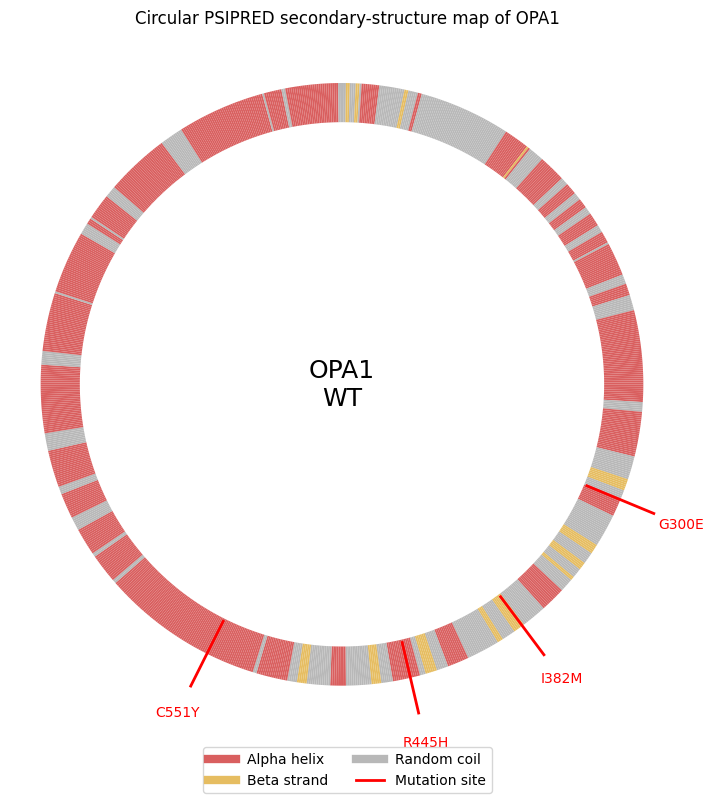

In [35]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge

# WT PSIPRED prediction file
path = "/content/OPA1_project/PSIPRED/WTOPA1/0b019d2e-5062-11f1-af7d-00163e100466.ss2"

# Read predicted secondary structure
residues = []
structures = []

with open(path) as f:
    for line in f:
        parts = line.split()
        if len(parts) >= 3 and parts[0].isdigit():
            residues.append(int(parts[0]))
            structures.append(parts[2])

# Colors for PSIPRED structure types
colors = {
    "H": "#d95f5f",  # alpha helix
    "E": "#e6bd61",  # beta strand
    "C": "#b8b8b8"   # coil
}

fig, ax = plt.subplots(figsize=(9, 9))
ax.set_aspect("equal")
ax.axis("off")

N = len(residues)
outer_radius = 1.0
ring_width = 0.13

# Draw one small segment per residue
for i, structure in enumerate(structures):
    theta1 = 90 - (i / N) * 360
    theta2 = 90 - ((i + 1) / N) * 360

    wedge = Wedge(
        (0, 0),
        outer_radius,
        theta2,
        theta1,
        width=ring_width,
        facecolor=colors.get(structure, "#b8b8b8"),
        edgecolor="none"
    )
    ax.add_patch(wedge)

# Mark mutation positions
mutation_positions = {
    "G300E": 300,
    "I382M": 382,
    "R445H": 445,
    "C551Y": 551
}

for mutation, position in mutation_positions.items():
    angle = np.deg2rad(90 - (position / N) * 360)
    r1, r2 = 0.88, 1.12

    ax.plot(
        [r1 * np.cos(angle), r2 * np.cos(angle)],
        [r1 * np.sin(angle), r2 * np.sin(angle)],
        color="red",
        linewidth=2
    )

    ax.text(
        1.22 * np.cos(angle),
        1.22 * np.sin(angle),
        mutation,
        color="red",
        ha="center",
        va="center",
        fontsize=10
    )

# Center label
ax.text(0, 0, "OPA1\nWT", ha="center", va="center", fontsize=18)

# Legend
legend_items = [
    plt.Line2D([0], [0], color=colors["H"], lw=6, label="Alpha helix"),
    plt.Line2D([0], [0], color=colors["E"], lw=6, label="Beta strand"),
    plt.Line2D([0], [0], color=colors["C"], lw=6, label="Random coil"),
    plt.Line2D([0], [0], color="red", lw=2, label="Mutation site")
]

ax.legend(handles=legend_items, loc="lower center",
          bbox_to_anchor=(0.5, -0.08), ncol=2)

plt.title("Circular PSIPRED secondary-structure map of OPA1", pad=20)
plt.savefig(
    "/content/OPA1_project/OPA1_circular_secondary_structure.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

PSIPRED residues loaded: 960


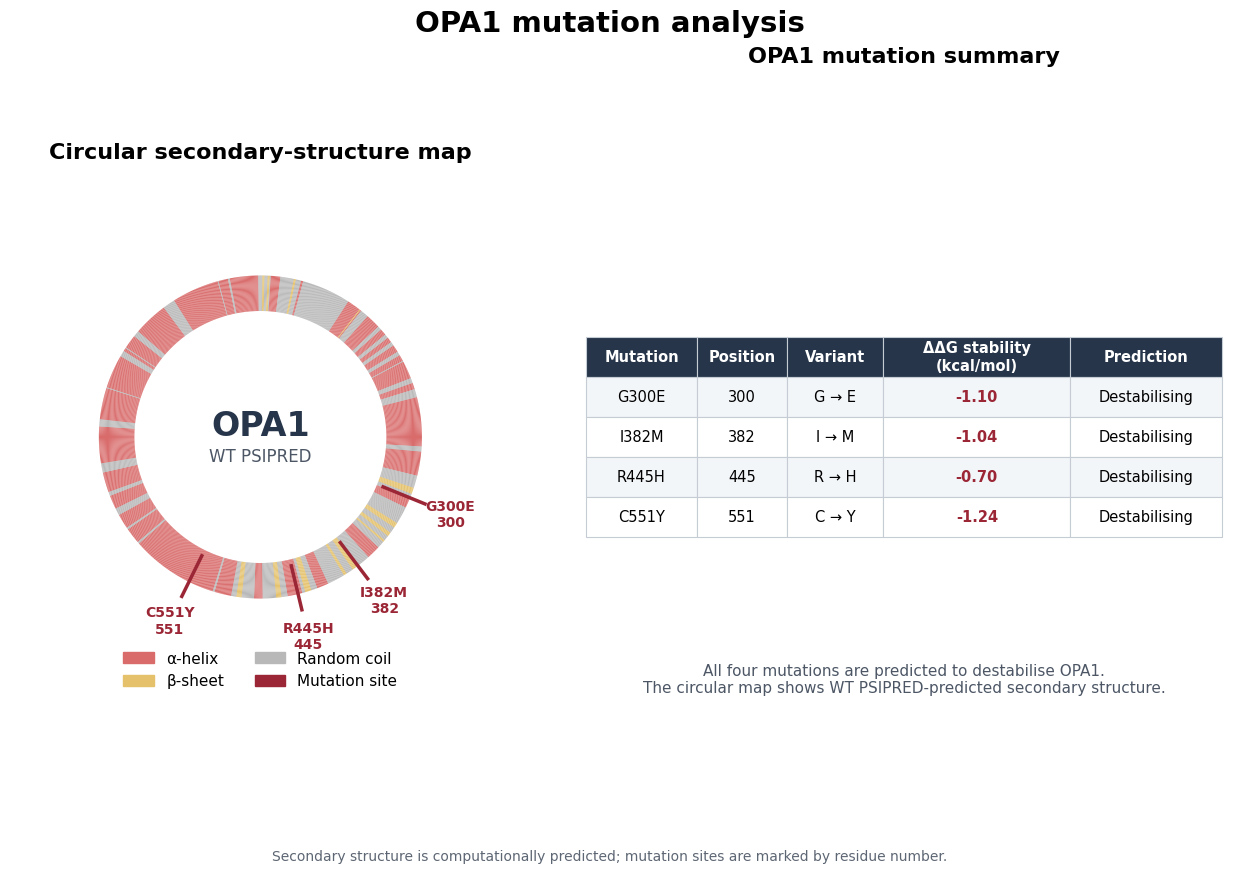

Figure saved to: /content/OPA1_project/OPA1_combined_circular_summary.png


In [36]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Patch
from matplotlib.gridspec import GridSpec

# -----------------------------
# 1. Read WT PSIPRED data
# -----------------------------
ss2_path = (
    "/content/OPA1_project/PSIPRED/WTOPA1/"
    "0b019d2e-5062-11f1-af7d-00163e100466.ss2"
)

if not os.path.exists(ss2_path):
    raise FileNotFoundError(
        "WT PSIPRED file not found. Please check the file path."
    )

residue_numbers = []
structures = []

with open(ss2_path) as file:
    for line in file:
        parts = line.split()
        if len(parts) >= 3 and parts[0].isdigit():
            residue_numbers.append(int(parts[0]))
            structures.append(parts[2])

N = len(structures)
print("PSIPRED residues loaded:", N)

# -----------------------------
# 2. Mutation data
# -----------------------------
mutations = [
    ("G300E", 300, "G → E", -1.10),
    ("I382M", 382, "I → M", -1.04),
    ("R445H", 445, "R → H", -0.70),
    ("C551Y", 551, "C → Y", -1.24),
]

# Colors
colors = {
    "H": "#d96b6b",  # alpha helix
    "E": "#e4c16a",  # beta sheet
    "C": "#b8b8b8",  # random coil
}

# -----------------------------
# 3. Create combined figure
# -----------------------------
fig = plt.figure(figsize=(16, 9), facecolor="white")
gs = GridSpec(
    1, 2,
    width_ratios=[1.05, 1.45],
    wspace=0.08,
    figure=fig
)

# Circular map
ax = fig.add_subplot(gs[0, 0])
ax.set_aspect("equal")
ax.axis("off")

# Draw residue-wise ring
for i, structure in enumerate(structures):
    angle1 = 90 - (i / N) * 360
    angle2 = 90 - ((i + 1) / N) * 360

    segment = Wedge(
        center=(0, 0),
        r=1.0,
        theta1=angle2,
        theta2=angle1,
        width=0.22,
        facecolor=colors.get(structure, colors["C"]),
        edgecolor="none"
    )
    ax.add_patch(segment)

# Add mutation markers
for name, position, variant, ddg in mutations:
    # Map the actual residue number to the angular position
    angle = np.deg2rad(90 - ((position - 1) / N) * 360)

    ax.plot(
        [0.82*np.cos(angle), 1.10*np.cos(angle)],
        [0.82*np.sin(angle), 1.10*np.sin(angle)],
        color="#9b2635",
        linewidth=2.5
    )

    ax.text(
        1.27*np.cos(angle),
        1.27*np.sin(angle),
        f"{name}\n{position}",
        ha="center",
        va="center",
        fontsize=10,
        color="#9b2635",
        fontweight="bold"
    )

ax.text(
    0, 0.07, "OPA1",
    ha="center", va="center",
    fontsize=24, fontweight="bold",
    color="#26354a"
)

ax.text(
    0, -0.12, "WT PSIPRED",
    ha="center", va="center",
    fontsize=12, color="#4c5665"
)

ax.set_xlim(-1.55, 1.55)
ax.set_ylim(-1.55, 1.55)

ax.set_title(
    "Circular secondary-structure map",
    fontsize=16, fontweight="bold", pad=20
)

legend_items = [
    Patch(color=colors["H"], label="α-helix"),
    Patch(color=colors["E"], label="β-sheet"),
    Patch(color=colors["C"], label="Random coil"),
    Patch(color="#9b2635", label="Mutation site")
]

ax.legend(
    handles=legend_items,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.03),
    ncol=2,
    frameon=False,
    fontsize=11
)

# -----------------------------
# 4. Results table
# -----------------------------
ax2 = fig.add_subplot(gs[0, 1])
ax2.axis("off")

ax2.set_title(
    "OPA1 mutation summary",
    fontsize=16, fontweight="bold", pad=20
)

column_labels = [
    "Mutation",
    "Position",
    "Variant",
    "ΔΔG stability\n(kcal/mol)",
    "Prediction"
]

table_data = [
    [name, str(position), variant, f"{ddg:.2f}", "Destabilising"]
    for name, position, variant, ddg in mutations
]

table = ax2.table(
    cellText=table_data,
    colLabels=column_labels,
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=[0.16, 0.13, 0.14, 0.27, 0.22]
)

table.auto_set_font_size(False)
table.set_fontsize(10.5)
table.scale(1.0, 2.4)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#c6ccd4")
    cell.set_linewidth(0.8)

    if row == 0:
        cell.set_facecolor("#26354a")
        cell.set_text_props(
            color="white",
            weight="bold"
        )
    else:
        cell.set_facecolor(
            "#f3f6f9" if row % 2 else "white"
        )

        if col == 3:
            cell.set_text_props(
                color="#9b2635",
                weight="bold"
            )

ax2.text(
    0.5, 0.15,
    "All four mutations are predicted to destabilise OPA1.\n"
    "The circular map shows WT PSIPRED-predicted secondary structure.",
    transform=ax2.transAxes,
    ha="center", va="center",
    fontsize=11, color="#4c5665"
)

# -----------------------------
# 5. Title and save
# -----------------------------
fig.suptitle(
    "OPA1 mutation analysis",
    fontsize=21,
    fontweight="bold",
    y=0.97
)

fig.text(
    0.5, 0.025,
    "Secondary structure is computationally predicted; "
    "mutation sites are marked by residue number.",
    ha="center",
    fontsize=10,
    color="#5d6673"
)

output_path = (
    "/content/OPA1_project/"
    "OPA1_combined_circular_summary.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved to:", output_path)

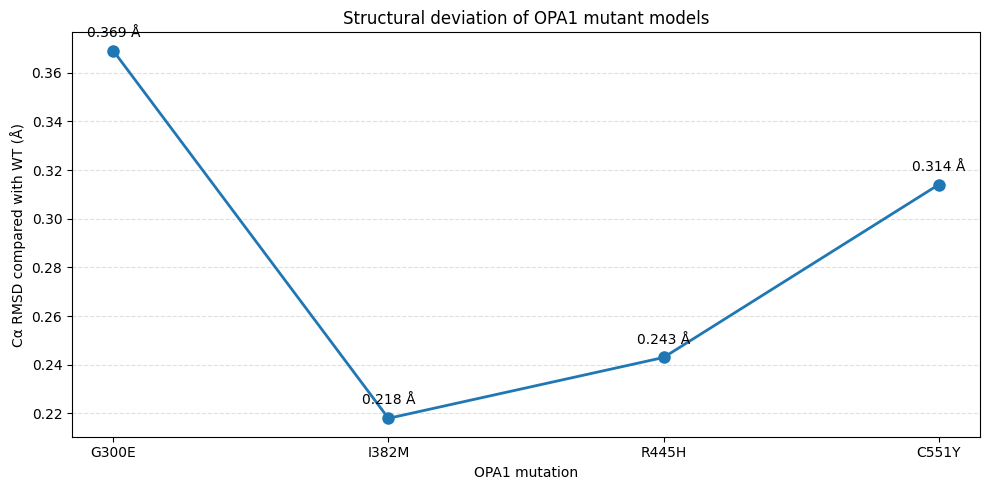

Saved: /content/OPA1_project/RMSD_line_graph.png


In [37]:
import matplotlib.pyplot as plt

mutations = ["G300E", "I382M", "R445H", "C551Y"]
rmsd = [0.369, 0.218, 0.243, 0.314]
aligned_atoms = [959, 960, 960, 960]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    mutations,
    rmsd,
    marker="o",
    linewidth=2,
    markersize=8
)

for i, value in enumerate(rmsd):
    ax.annotate(
        f"{value:.3f} Å",
        (i, value),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

ax.set_xlabel("OPA1 mutation")
ax.set_ylabel("Cα RMSD compared with WT (Å)")
ax.set_title("Structural deviation of OPA1 mutant models")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

output = "/content/OPA1_project/RMSD_line_graph.png"
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output)

In [38]:
import os
import shutil

project = "/content/OPA1_project"
final_folder = os.path.join(project, "FINAL_FIGURES")
os.makedirs(final_folder, exist_ok=True)

figures = [
    "DYNAMUT2_stability.png",
    "DYNAMUT2_stability_summary.png",
    "PSIPRED_secondary_structure.png",
    "PSIPRED_secondary_structure_marked.png",
    "RMSD_comparison.png",
    "OPA1_combined_circular_summary.png",
    "RMSD_line_graph.png"
]

for filename in figures:
    source = os.path.join(project, filename)

    if os.path.exists(source):
        shutil.copy2(source, final_folder)
        print("Added:", filename)
    else:
        print("Not found:", filename)

print("\nAll available figures are in:", final_folder)

Added: DYNAMUT2_stability.png
Added: DYNAMUT2_stability_summary.png
Added: PSIPRED_secondary_structure.png
Added: PSIPRED_secondary_structure_marked.png
Added: RMSD_comparison.png
Added: OPA1_combined_circular_summary.png
Added: RMSD_line_graph.png

All available figures are in: /content/OPA1_project/FINAL_FIGURES


In [39]:
import shutil

zip_path = shutil.make_archive(
    "/content/OPA1_project/OPA1_FINAL_FIGURES",
    "zip",
    root_dir="/content/OPA1_project",
    base_dir="FINAL_FIGURES"
)

print("ZIP created:", zip_path)

ZIP created: /content/OPA1_project/OPA1_FINAL_FIGURES.zip


In [40]:
from google.colab import files
files.download("/content/OPA1_project/OPA1_FINAL_FIGURES.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
import os

folder = "/content/OPA1_project/FINAL_FIGURES"

for filename in sorted(os.listdir(folder)):
    print(filename)

DYNAMUT2_stability.png
DYNAMUT2_stability_summary.png
OPA1_combined_circular_summary.png
PSIPRED_secondary_structure.png
PSIPRED_secondary_structure_marked.png
RMSD_comparison.png
RMSD_line_graph.png


In [42]:
from google.colab import files
files.download("/content/OPA1_project/OPA1_FINAL_FIGURES.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
import shutil

shutil.make_archive(
    "/content/OPA1_project/OPA1_FINAL_FIGURES",
    "zip",
    root_dir="/content/OPA1_project",
    base_dir="FINAL_FIGURES"
)

'/content/OPA1_project/OPA1_FINAL_FIGURES.zip'